# 09 · Volatility of BTC and ETH: level, tails, clustering, √t and the weekend

Module **M4: volatility** (Phase 1).

**Task.** Measure how much BTC and ETH move, with daily and hourly candles from 2018 to the last
complete day. No strategy is tested here: this notebook only describes the data.

**Markets.** Binance **spot** BTC/USDT and ETH/USDT, daily and hourly candles, open times from
2018-01-01 00:00 UTC to 2026-11-23 23:00 UTC (2026-11-23 is the last complete UTC day).

**Questions (one row each in the Findings table at the end).**

| | Question |
|---|---|
| H1 | How high is the 30-day volatility of BTC and ETH today, compared with 2018–2026? How does it look around the marked dates? |
| H2 | How does ETH's volatility compare with BTC's, and how correlated are their daily returns, year by year? |
| H3 | How often are there days beyond 2, 3, 4 and 5 past-only σ, compared with a normal distribution? |
| H4 | Do large moves come in streaks (autocorrelation of r and \|r\|, P(big today \| big yesterday))? |
| H5 | Does the √t rule hold in this data (hourly → daily, daily → weekly)? |
| H6 | Is volatility different on weekends, and by hour of the day and day of the week? |
| H7 | How large is notebook 07's round-trip cost compared with a typical BTC move over 1 hour, 1 day and 1 week? |

No hypotheses were recorded for these questions. The notebook does not test causes.

**Definitions (fixed before looking at the data).**

- **Simple return:** $r_t = \text{close}_t / \text{close}_{t-1} - 1$ (not logarithmic).
- **Volatility:** the standard deviation of simple returns, `ddof=1` (sample std).
- **Annualization:** crypto trades every day, so a daily σ is multiplied by √365 and an hourly σ
  by √(365·24). The stock-market convention √252 is shown once, only as a comparison.
- **Past-only σ:** $\sigma_{t-1}$ = std of the **30 daily returns before day t** (day t is not in
  it). Each day is measured in units of that σ: $z_t = r_t / \sigma_{t-1}$. This only uses what was
  known at the open of day t, so it has no look-ahead. A σ over the full sample would use the
  future; it appears once, labelled **"full-sample (look-ahead, for reference only)"**.
- **Big day:** $|z_t| > 2$ (past-only).

**Conventions.** All times are UTC. A candle is labelled by its **open time**: the daily candle
of 2026-11-23 covers 2026-11-23 00:00 → 2026-11-24 00:00 UTC. "CDMX" means UTC−6.

## 0. Setup and data

The downloader is the same one notebooks 01–04 use (`src/data/ohlcv.py`, through ccxt). The only
change for this notebook is that it now also accepts hourly candles (`timeframe="1h"`).
Downloads are cached in `data/09_volatility/` (gitignored); a re-run reads the cache.

In [1]:
%matplotlib inline
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.data.ohlcv import cache_path, fetch_ohlcv_window, load_or_fetch_window
from src.volatility import (DAYS_PER_YEAR, HOURS_PER_YEAR, TRADING_DAYS_STOCKS, acf,
                            acf_robust_band, annualize,
                            conditional_big_day, normal_two_sided_tail, past_only_z, rolling_vol,
                            sqrt_t_by_group, sqrt_t_null_ratio, step_returns,
                            tail_table, week_sunday, weekly_returns_from_daily)

DATA_DIR = REPO_ROOT / "data" / "09_volatility"
START_UTC = "2018-01-01"
END_UTC = "2026-11-24"            # excluded: the last candle kept opens on 2026-11-23
NOW_UTC = "2026-11-24 00:05"      # fixed "now", so a re-run drops exactly the same candles
LABEL = "2018-01-01_2026-11-23"   # part of the cache file name
SYMBOLS = {"BTC": "BTC/USDT", "ETH": "ETH/USDT"}
STEP = {"1d": pd.Timedelta(days=1), "1h": pd.Timedelta(hours=1)}
WINDOW = 30                       # days in the rolling and past-only σ
BIG_Z = 2.0                       # "big day" threshold, in past-only σ
BIG_MOVE = 0.08                   # |return| >= 8% for the big-move list (Part 3)
CDMX_OFFSET_H = -6                # CDMX = UTC-6

EVENTS = {                        # dates marked on the charts (labels from the brief)
    "2020-03-12": "2020-03-12",
    "2025-10-10": "2025-10-10",
    "2026-10-29": "2026-10-29 Binance hack",
    "2026-11-23": "2026-11-23 last day",
}

COLORS = {"BTC": "#2a78d6", "ETH": "#eb6834"}   # categorical slots 1 and 2 of the palette
MUTED = "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "figure.dpi": 110,
                     "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)


def pct(x, digits=2):
    """Format a fraction as a percent string (0.0123 -> '1.23%')."""
    return f"{100 * x:.{digits}f}%"

In [2]:
candles, infos = {}, {}
for timeframe in ["1d", "1h"]:
    for asset, symbol in SYMBOLS.items():
        path = cache_path(DATA_DIR, "binance", symbol, timeframe, LABEL)
        df, info = load_or_fetch_window(
            path, lambda: fetch_ohlcv_window("binance", symbol, START_UTC, END_UTC,
                                             timeframe=timeframe, now_utc=NOW_UTC))
        candles[(asset, timeframe)], infos[(asset, timeframe)] = df, info

coverage = []
missing_by = {}
for (asset, timeframe), df in candles.items():
    expected = pd.date_range(START_UTC, pd.Timestamp(END_UTC) - STEP[timeframe],
                             freq=STEP[timeframe], tz="UTC")
    missing = expected.difference(df.index)
    missing_by[(asset, timeframe)] = missing
    coverage.append({
        "asset": asset, "timeframe": timeframe,
        "first open (UTC)": df.index.min(), "last open (UTC)": df.index.max(),
        "expected candles": len(expected), "candles": len(df), "missing": len(missing),
        "coverage (%)": round(100 * len(df.index.intersection(expected)) / len(expected), 3),
        "duplicates dropped": infos[(asset, timeframe)]["duplicates_dropped"],
        "duplicates left": int(df.index.duplicated().sum()),
        "zero-volume candles": int((df["volume"] == 0).sum()),
    })
pd.DataFrame(coverage).set_index(["asset", "timeframe"])

,,first open (UTC),last open (UTC),expected candles,candles,missing,coverage (%),duplicates dropped,duplicates left,zero-volume candles
asset,timeframe,,,,,,,,,
BTC,1d,2018-01-01 00:00:00+00:00,2026-11-23 00:00:00+00:00,3249,3249,0,100.000,0,0,0
ETH,1d,2018-01-01 00:00:00+00:00,2026-11-23 00:00:00+00:00,3249,3249,0,100.000,0,0,0
BTC,1h,2018-01-01 00:00:00+00:00,2026-11-23 23:00:00+00:00,77976,77854,122,99.844,0,0,3
ETH,1h,2018-01-01 00:00:00+00:00,2026-11-23 23:00:00+00:00,77976,77854,122,99.844,0,0,3


**Missing hours, grouped into runs.** A run is a block of consecutive missing hourly candles. The
table also checks whether BTC and ETH miss exactly the same hours (the same exchange-wide pause
would remove both).

In [3]:
def missing_runs(missing, step):
    """Group missing timestamps into runs of consecutive candles."""
    s = pd.Series(missing)
    run_id = s.diff().ne(step).cumsum().to_numpy()
    return s.groupby(run_id).agg(first_missing="min", last_missing="max", candles="size")


runs = missing_runs(missing_by[("BTC", "1h")], STEP["1h"]).reset_index(drop=True)
same_hours = missing_by[("BTC", "1h")].equals(missing_by[("ETH", "1h")])
print(f"BTC and ETH miss exactly the same hours: {same_hours}")
print(f"Missing hourly runs: {len(runs)}, years: {sorted(int(y) for y in runs['first_missing'].dt.year.unique())}")
runs

BTC and ETH miss exactly the same hours: True
Missing hourly runs: 27, years: [2018, 2019, 2020, 2021, 2023]


,first_missing,last_missing,candles
0,2018-01-04 04:00:00+00:00,2018-01-04 04:00:00+00:00,1
1,2018-02-08 01:00:00+00:00,2018-02-09 09:00:00+00:00,33
2,2018-06-26 02:00:00+00:00,2018-06-26 11:00:00+00:00,10
3,2018-06-27 13:00:00+00:00,2018-06-27 13:00:00+00:00,1
4,2018-07-04 01:00:00+00:00,2018-07-04 07:00:00+00:00,7
5,2018-10-19 06:00:00+00:00,2018-10-19 08:00:00+00:00,3
6,2018-11-14 02:00:00+00:00,2018-11-14 08:00:00+00:00,7
7,2019-03-12 02:00:00+00:00,2019-03-12 07:00:00+00:00,6
8,2019-05-15 03:00:00+00:00,2019-05-15 12:00:00+00:00,10
9,2019-08-15 02:00:00+00:00,2019-08-15 09:00:00+00:00,8


**Consistency check between the two timeframes.** The daily close should be the close of that
day's 23:00 hourly candle (both are the last trade before 24:00 UTC). If they match, daily and
hourly returns describe the same prices.

In [4]:
check = []
for asset in SYMBOLS:
    d = candles[(asset, "1d")]["close"]
    h23 = candles[(asset, "1h")]["close"]
    h23 = h23[h23.index.hour == 23]
    h23.index = h23.index.floor("D")
    both = d.index.intersection(h23.index)
    gap = (d.loc[both] / h23.loc[both] - 1).abs()
    check.append({"asset": asset, "days compared": len(both),
                  "days without a 23:00 candle": len(d) - len(both),
                  "days where closes differ": int((gap > 1e-12).sum()),
                  "max |difference| (%)": 100 * gap.max()})
pd.DataFrame(check).set_index("asset")

,days compared,days without a 23:00 candle,days where closes differ,max |difference| (%)
asset,,,,
BTC,3248,1,0,0.0
ETH,3248,1,0,0.0


### 0.1 Returns

Daily returns use consecutive daily candles; hourly returns use consecutive hourly candles. A
return is only computed when the previous candle is exactly one step earlier.
**Post-inspection:** across a missing hour, the return would cover several hours and look like an
outlier, so it is left empty (NaN) instead. Both series are put on a regular grid (one row per
day / hour), so "the previous row" always means "the previous period".

In [5]:
daily = {a: step_returns(candles[(a, "1d")]["close"], STEP["1d"]).asfreq("D") for a in SYMBOLS}
hourly = {a: step_returns(candles[(a, "1h")]["close"], STEP["1h"]).asfreq("h") for a in SYMBOLS}

summary = []
for name, series, per_year in [("daily", daily, DAYS_PER_YEAR), ("hourly", hourly, HOURS_PER_YEAR)]:
    for a, r in series.items():
        summary.append({"returns": name, "asset": a, "first": str(r.index.min()), "last": str(r.index.max()),
                        "rows": len(r), "valid": int(r.notna().sum()), "empty (gap)": int(r.isna().sum()),
                        "mean (%)": 100 * r.mean(), "std (%)": 100 * r.std(ddof=1),
                        "annualized std (%)": 100 * annualize(r.std(ddof=1), per_year)})
pd.DataFrame(summary).set_index(["returns", "asset"]).round(3)

first                       last   rows  valid  empty (gap)  mean (%)  std (%)  annualized std (%)
returns asset                                                                                                                        
daily   BTC    2018-01-02 00:00:00+00:00  2026-11-23 00:00:00+00:00   3248   3248            0     0.104    3.346              63.932
        ETH    2018-01-02 00:00:00+00:00  2026-11-23 00:00:00+00:00   3248   3248            0     0.124    4.409              84.229
hourly  BTC    2018-01-01 01:00:00+00:00  2026-11-23 23:00:00+00:00  77975  77826          149     0.004    0.708              66.234
        ETH    2018-01-01 01:00:00+00:00  2026-11-23 23:00:00+00:00  77975  77826          149     0.005    0.902              84.447

**√365 vs √252, once.** The same daily σ (the last 30 days) is annualized both ways. The ratio
does not depend on the data: it is always √(365/252).

In [6]:
rows = []
for a in SYMBOLS:
    sigma_d = rolling_vol(daily[a], WINDOW).iloc[-1]
    rows.append({"asset": a, "daily σ, last 30 d (%)": 100 * sigma_d,
                 "× √365 (%)": 100 * annualize(sigma_d, DAYS_PER_YEAR),
                 "× √252 (%) — stocks convention, comparison only": 100 * annualize(sigma_d, TRADING_DAYS_STOCKS),
                 "ratio √365 / √252": math.sqrt(DAYS_PER_YEAR / TRADING_DAYS_STOCKS)})
pd.DataFrame(rows).set_index("asset").round(3)

,"daily σ, last 30 d (%)",× √365 (%),"× √252 (%) — stocks convention, comparison only",ratio √365 / √252
asset,,,,
BTC,2.415,46.143,38.341,1.204
ETH,3.387,64.715,53.773,1.204


## Part 1 — Volatility over time (H1)

**30-day rolling volatility, annualized.** The value at day t is the std of the 30 daily returns
ending **at** day t (t included), × √365. It describes the recent past at the end of each day; it
is a chart, not a signal. The first value needs 30 returns, so the line starts at the end of
January 2018. The lower panel zooms in on the last fifteen months so that the last two marked dates do not
overlap.

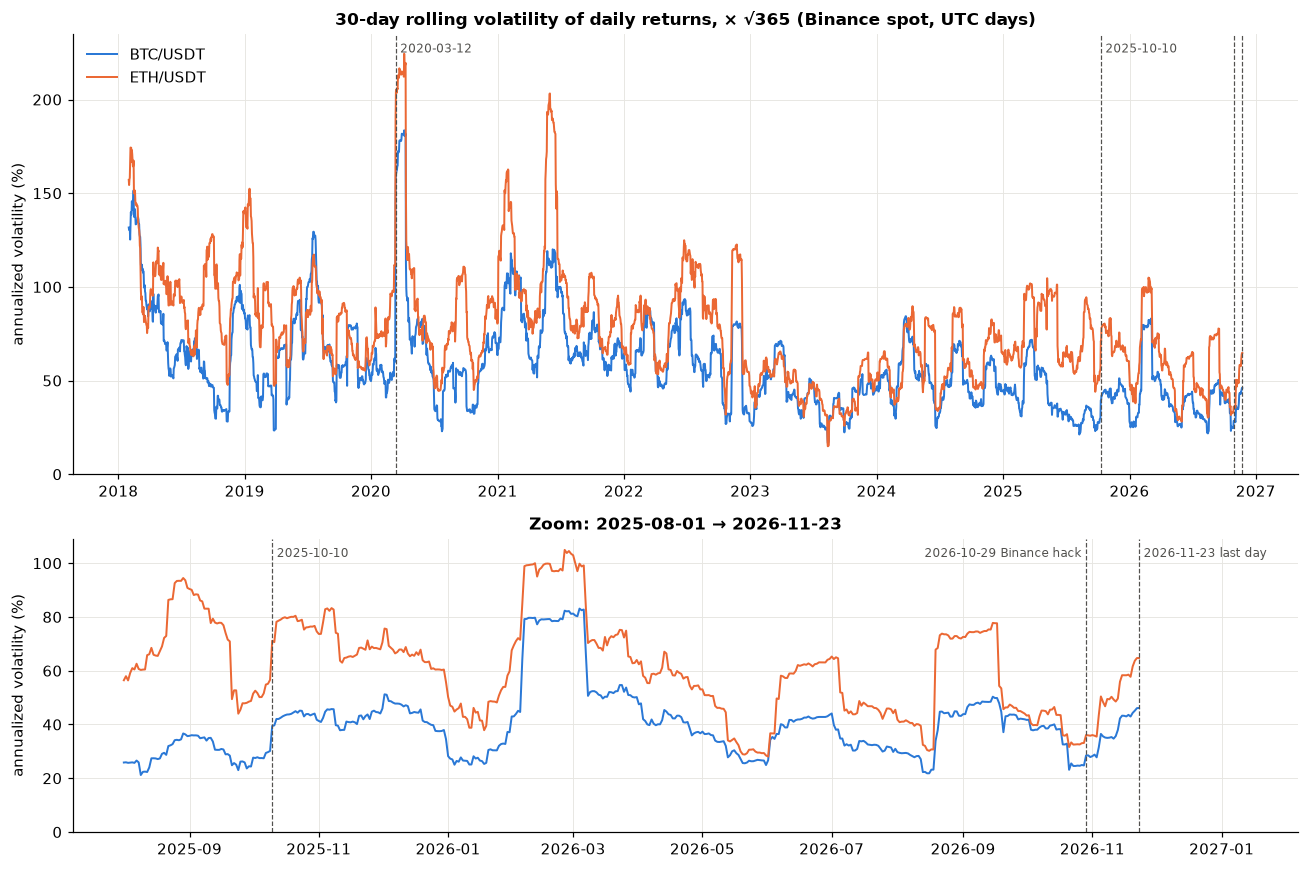

In [7]:
vol30 = pd.DataFrame({a: annualize(rolling_vol(daily[a], WINDOW), DAYS_PER_YEAR) for a in SYMBOLS})

fig, axes = plt.subplots(2, 1, figsize=(12, 8), gridspec_kw={"height_ratios": [3, 2]})
zoom_start = pd.Timestamp("2025-08-01", tz="UTC")
for ax, data, label_events in [(axes[0], vol30, ["2020-03-12", "2025-10-10"]),
                               (axes[1], vol30.loc[zoom_start:], ["2025-10-10", "2026-10-29", "2026-11-23"])]:
    for a in SYMBOLS:
        ax.plot(data.index, 100 * data[a], color=COLORS[a], lw=1.3, label=f"{a}/USDT")
    for i, (day, text) in enumerate(EVENTS.items()):
        t = pd.Timestamp(day, tz="UTC")
        if t < data.index.min():
            continue
        ax.axvline(t, color=MUTED, lw=0.8, ls="--")
        if day in label_events:
            left = day == "2026-10-29"   # two close dates: one label on each side of its line
            ax.annotate(text, (t, 1), xycoords=("data", "axes fraction"),
                        xytext=(-3 if left else 3, -12), textcoords="offset points",
                        fontsize=8, color=MUTED, ha="right" if left else "left")
    ax.set_ylabel("annualized volatility (%)")
    ax.set_ylim(bottom=0)
axes[0].set_title("30-day rolling volatility of daily returns, × √365 (Binance spot, UTC days)")
axes[1].set_title("Zoom: 2025-08-01 → 2026-11-23")
axes[1].set_xlim(right=vol30.index[-1] + pd.Timedelta(days=75))   # room for the last label
axes[0].legend(loc="upper left", frameon=False)
fig.tight_layout()
plt.show()

**The marked dates in numbers.** For each marked day: that day's return, its past-only z (the 30
days before it), and the 30-day volatility at the end of the day (which includes it).

In [8]:
z = {a: past_only_z(daily[a], WINDOW) for a in SYMBOLS}
rows = []
for day, text in EVENTS.items():
    t = pd.Timestamp(day, tz="UTC")
    for a in SYMBOLS:
        rows.append({"date (UTC)": text, "asset": a, "return (%)": 100 * daily[a].loc[t],
                     "z (past-only)": z[a].loc[t], "30-d vol at end of day (%)": 100 * vol30[a].loc[t]})
pd.DataFrame(rows).set_index(["date (UTC)", "asset"]).round(2)

return (%)  z (past-only)  30-d vol at end of day (%)
date (UTC)              asset                                                       
2020-03-12              BTC        -39.50         -12.57                      146.81
                        ETH        -44.60          -7.64                      188.56
2025-10-10              BTC         -7.31          -4.63                       39.46
                        ETH        -12.33          -4.16                       71.15
2026-10-29 Binance hack BTC         -4.12          -3.18                       28.46
                        ETH         -4.52          -2.60                       36.08
2026-11-23 last day     BTC         -0.00          -0.00                       46.14
                        ETH         -0.79          -0.23                       64.72

**Current volatility and its percentile.** "Current" is the 30-day window ending on 2026-11-23
(returns of 2026-10-25 → 2026-11-23). The percentile is the share of all 30-day windows since 2018
whose volatility is **at or below** the current one. All of those windows end on or before today,
so this is not look-ahead.

In [9]:
current = []
for a in SYMBOLS:
    v = vol30[a].dropna()
    current.append({"asset": a, "window": f"{daily[a].index[-WINDOW].date()} → {v.index[-1].date()}",
                    "current 30-d vol (%)": 100 * v.iloc[-1],
                    "percentile within 2018–2026 (%)": 100 * (v <= v.iloc[-1]).mean(),
                    "n windows": len(v),
                    "min (%)": 100 * v.min(), "min date": v.idxmin().date(),
                    "median (%)": 100 * v.median(),
                    "max (%)": 100 * v.max(), "max date": v.idxmax().date()})
current = pd.DataFrame(current).set_index("asset")
current.round(1)

,window,current 30-d vol (%),percentile within 2018–2026 (%),n windows,min (%),min date,median (%),max (%),max date
asset,,,,,,,,,
BTC,2026-10-25 → 2026-11-23,46.1,35.2,3219,16.7,2023-08-13,53.5,183.6,2020-04-06
ETH,2026-10-25 → 2026-11-23,64.7,37.0,3219,14.9,2023-08-13,74.1,224.4,2020-04-06


**Annualized volatility by calendar year.** The std of all daily returns of each year, × √365.
2018 starts on 2018-01-02 (the first return needs the close of 2018-01-01) and 2026 ends on
2026-11-23, so both are partial years; the column `n days` shows how many returns each year has.

In [10]:
year_of = lambda s: s.index.year
annual = pd.DataFrame({
    **{f"{a} vol (%)": daily[a].groupby(year_of(daily[a])).std(ddof=1) * 100 * math.sqrt(DAYS_PER_YEAR)
       for a in SYMBOLS},
    "n days": daily["BTC"].groupby(year_of(daily["BTC"])).count(),
})
annual.index.name = "year (UTC)"
annual.round(1)

,BTC vol (%),ETH vol (%),n days
year (UTC),,,
2018,83.1,109.8,364
2019,68.6,80.4,365
2020,75.5,99.0,366
2021,81.1,108.3,365
2022,63.7,86.7,365
2023,44.1,46.9,365
2024,53.1,64.8,366
2025,41.7,74.9,365
2026,45.1,61.3,327


## Part 2 — BTC vs ETH (H2)

**Volatility ratio ETH / BTC.** The 30-day volatility of ETH divided by BTC's, day by day. Above 1
means ETH moved more than BTC in that window. The √365 factor cancels in a ratio.

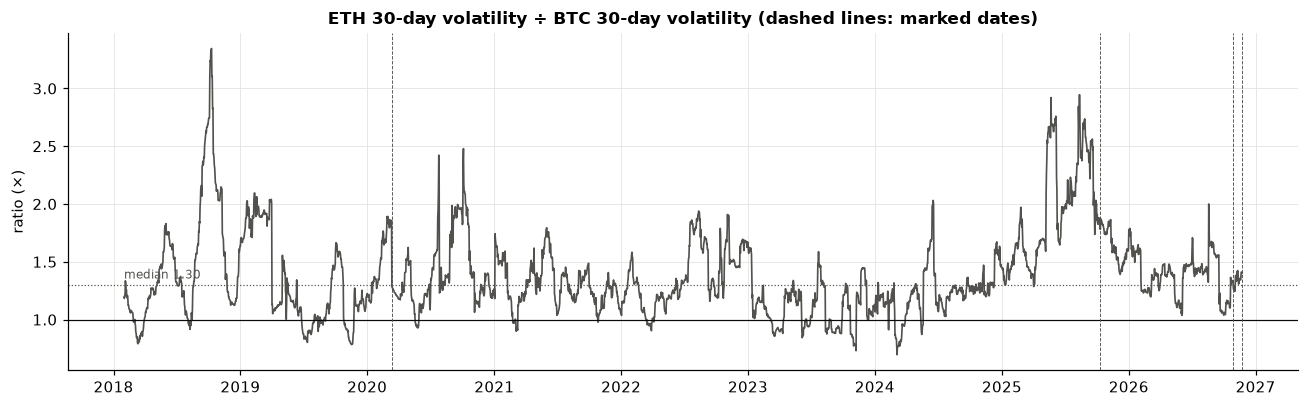

Share of days with ratio > 1: 89.7% of 3219 days


In [11]:
ratio30 = (vol30["ETH"] / vol30["BTC"]).dropna()
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(ratio30.index, ratio30, color=MUTED, lw=1.1)
ax.axhline(1, color="#0b0b0b", lw=0.8)
ax.axhline(ratio30.median(), color=MUTED, lw=0.8, ls=":")
ax.annotate(f"median {ratio30.median():.2f}", (ratio30.index[0], ratio30.median()),
            xytext=(0, 4), textcoords="offset points", fontsize=8, color=MUTED)
for day in EVENTS:
    ax.axvline(pd.Timestamp(day, tz="UTC"), color=MUTED, lw=0.6, ls="--")
ax.set_title("ETH 30-day volatility ÷ BTC 30-day volatility (dashed lines: marked dates)")
ax.set_ylabel("ratio (×)")
fig.tight_layout()
plt.show()
print(f"Share of days with ratio > 1: {100 * (ratio30 > 1).mean():.1f}% of {len(ratio30)} days")

**By year:** volatility of each asset, their ratio, and the Pearson correlation of BTC and ETH
daily returns (same UTC days). The last row uses all days together.

In [12]:
both = pd.DataFrame(daily).dropna()
by_year = both.groupby(both.index.year)
pair = pd.DataFrame({
    "BTC vol (%)": by_year["BTC"].std() * 100 * math.sqrt(DAYS_PER_YEAR),
    "ETH vol (%)": by_year["ETH"].std() * 100 * math.sqrt(DAYS_PER_YEAR),
    "corr BTC–ETH": by_year.apply(lambda g: g["BTC"].corr(g["ETH"])),
    "n days": by_year.size(),
})
pair.loc["all"] = [both["BTC"].std() * 100 * math.sqrt(DAYS_PER_YEAR),
                   both["ETH"].std() * 100 * math.sqrt(DAYS_PER_YEAR),
                   both["BTC"].corr(both["ETH"]), len(both)]
pair.insert(2, "ratio ETH/BTC", pair["ETH vol (%)"] / pair["BTC vol (%)"])
pair["n days"] = pair["n days"].astype(int)
pair.index.name = "year (UTC)"
pair.round(2)

,BTC vol (%),ETH vol (%),ratio ETH/BTC,corr BTC–ETH,n days
year (UTC),,,,,
2018,83.13,109.83,1.32,0.82,364
2019,68.63,80.45,1.17,0.81,365
2020,75.48,99.01,1.31,0.85,366
2021,81.10,108.29,1.34,0.76,365
2022,63.74,86.73,1.36,0.89,365
2023,44.06,46.85,1.06,0.83,365
2024,53.08,64.85,1.22,0.79,366
2025,41.69,74.95,1.80,0.82,365
2026,45.08,61.32,1.36,0.92,327


## Part 3 — Tails (H3)

**Histogram of z (past-only) vs the standard normal and t(29).** If daily returns were normal with
a σ equal to the last 30 days' σ, the bars would follow the dashed curve (N(0, 1)). Because σ is
itself estimated from only 30 days, the fair "no fat tails" reference is the dotted t(29) curve
(explained with the table below); the two curves only differ visibly in the tails. The top row has a linear
y-axis (the centre of the distribution); the bottom row has a log y-axis, which makes the rare
days in the tails visible. Days beyond ±8 are counted in the text, not drawn.

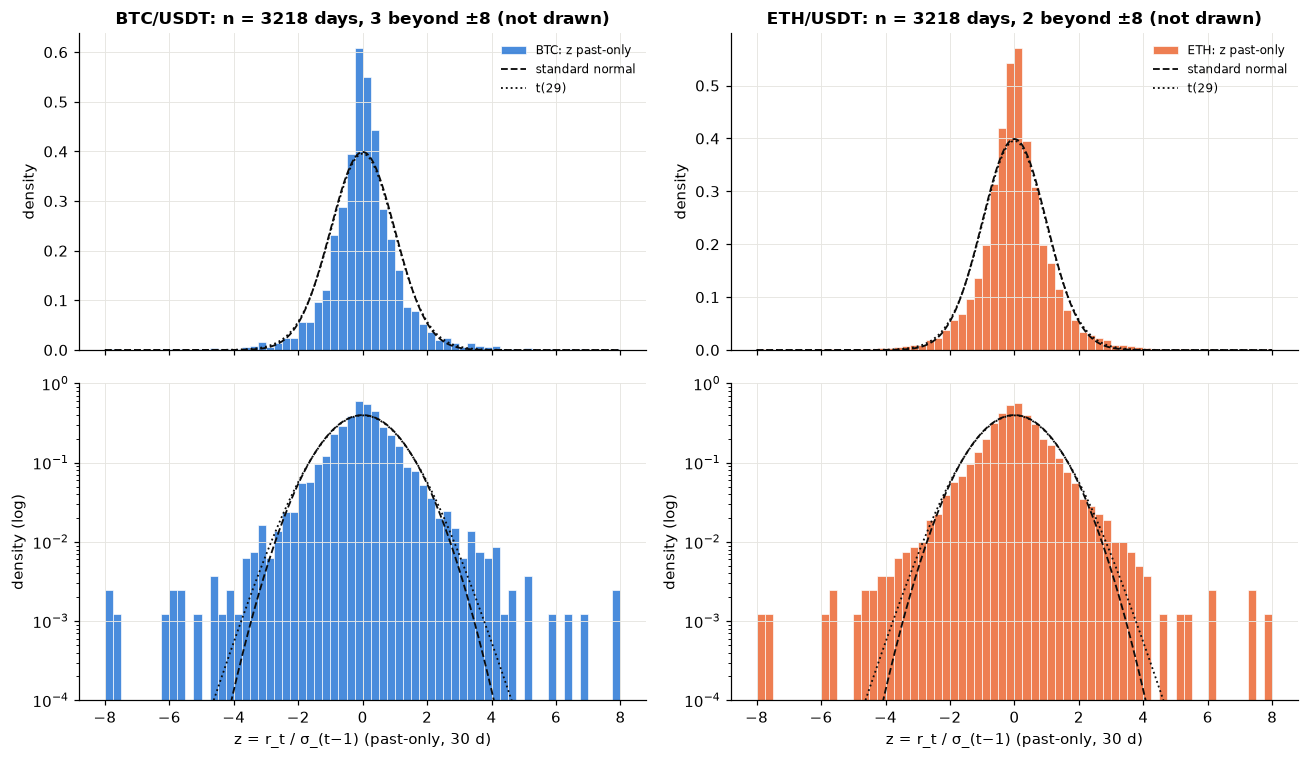

In [13]:
bins = np.arange(-8, 8.25, 0.25)
grid = np.linspace(-8, 8, 400)
normal_pdf = np.exp(-grid ** 2 / 2) / math.sqrt(2 * math.pi)
DF = WINDOW - 1
t_pdf = np.exp(math.lgamma((DF + 1) / 2) - math.lgamma(DF / 2) - 0.5 * math.log(DF * math.pi)
               - (DF + 1) / 2 * np.log1p(grid ** 2 / DF))
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for col, a in enumerate(SYMBOLS):
    zz = z[a].dropna()
    outside = int((zz.abs() > 8).sum())
    for row, log in enumerate([False, True]):
        ax = axes[row, col]
        ax.hist(zz.clip(-8, 8), bins=bins, density=True, color=COLORS[a], alpha=0.85,
                edgecolor="white", linewidth=0.5, label=f"{a}: z past-only")
        ax.plot(grid, normal_pdf, color="#0b0b0b", lw=1.2, ls="--", label="standard normal")
        ax.plot(grid, t_pdf, color="#0b0b0b", lw=1.2, ls=":", label="t(29)")
        if log:
            ax.set_yscale("log")
            ax.set_ylim(1e-4, 1)
            ax.set_xlabel("z = r_t / σ_(t−1) (past-only, 30 d)")
        ax.set_ylabel("density" + (" (log)" if log else ""))
    axes[0, col].set_title(f"{a}/USDT: n = {len(zz)} days, {outside} beyond ±8 (not drawn)")
    axes[0, col].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

**Days with |z| > 2, 3, 4, 5: observed vs expected under a normal.** `expected_normal` = n × P(|Z| > k)
for a standard normal Z. `observed_over_expected` above 1 means more extreme days than a normal
predicts.

**Post-inspection: `expected_t29`.** σ is *estimated* from only 30 days, and an estimate can come out
too low by chance. Even if returns were exactly normal, z = r / σ̂ would then follow a Student-t
distribution with 29 degrees of freedom, which has fatter tails than N(0, 1). `expected_t29` is the
count under that distribution: a fairer "no fat tails" baseline for the past-only z.

The rows labelled **full-sample (look-ahead, for reference only)** divide every return by
the std of the whole 2018–2026 sample, which nobody knew in 2018: they are there only to show how
much the choice of σ changes the counts.

In [14]:
tails = []
for a in SYMBOLS:
    t_past = tail_table(z[a], t_df=WINDOW - 1).assign(asset=a, sigma="past-only (30 d)")
    z_full = daily[a] / daily[a].std(ddof=1)
    t_full = tail_table(z_full.loc[z[a].dropna().index]).assign(
        asset=a, sigma="full-sample (look-ahead, for reference only)")
    tails += [t_past, t_full]
tails = pd.concat(tails).reset_index().set_index(["asset", "sigma", "threshold"])
tails = tails[["n_days", "observed", "expected_normal", "expected_t29", "observed_over_expected"]]
tails["observed_over_expected_t29"] = tails["observed"] / tails["expected_t29"]
tails.round({"expected_normal": 4, "expected_t29": 4, "observed_over_expected": 1,
             "observed_over_expected_t29": 1})

n_days  observed  expected_normal  expected_t29  observed_over_expected  \
asset sigma                                        threshold                                                                            
BTC   past-only (30 d)                             |z| > 2      3218       216         146.4198      176.8086                     1.5   
                                                   |z| > 3      3218        85           8.6879       17.6964                     9.8   
                                                   |z| > 4      3218        33           0.2038        1.2874                   161.9   
                                                   |z| > 5      3218        17           0.0018        0.0816                  9214.6   
      full-sample (look-ahead, for reference only) |z| > 2      3218       177         146.4198           NaN                     1.2   
                                                   |z| > 3      3218        57           8.6879           NaN                     6.6   
                                                   |z| > 4      3218        15           0.2038           NaN                    73.6   
                                                   |z| > 5      3218         4           0.0018           NaN                  2168.2   
ETH   past-only (30 d)                             |z| > 2      3218       227         146.4198      176.8086                     1.6   
                                                   |z| > 3      3218        71           8.6879       17.6964                     8.2   
                                                   |z| > 4      3218        24           0.2038        1.2874                   117.7   
                                                   |z| > 5      3218        12           0.0018        0.0816                  6504.5   
      full-sample (look-ahead, for reference only) |z| > 2      3218       164         146.4198           NaN                     1.1   
                                                   |z| > 3      3218        49           8.6879           NaN                     5.6   
                                                   |z| > 4      3218        13           0.2038           NaN                    63.8   
                                                   |z| > 5      3218         5           0.0018           NaN                  2710.2   

                                                              observed_over_expected_t29  
asset sigma                                        threshold                              
BTC   past-only (30 d)                             |z| > 2                           1.2  
                                                   |z| > 3                           4.8  
                                                   |z| > 4                          25.6  
                                                   |z| > 5                         208.3  
      full-sample (look-ahead, for reference only) |z| > 2                           NaN  
                                                   |z| > 3                           NaN  
                                                   |z| > 4                           NaN  
                                                   |z| > 5                           NaN  
ETH   past-only (30 d)                             |z| > 2                           1.3  
                                                   |z| > 3                           4.0  
                                                   |z| > 4                          18.6  
                                                   |z| > 5                         147.0  
      full-sample (look-ahead, for reference only) |z| > 2                           NaN  
                                                   |z| > 3                           NaN  
                                                   |z| > 4                           NaN  
                                                

**Days with |return| ≥ 8%, counted by year.** This threshold is in percent, not in σ, so a calm
year and a wild year are judged with the same ruler.

In [15]:
big_rows = []
for a in SYMBOLS:
    r = daily[a].dropna()
    big = r[r.abs() >= BIG_MOVE]
    big_rows.append(pd.DataFrame({"asset": a, "year": big.index.year, "up": big > 0}))
big_moves = pd.concat(big_rows)
counts = (big_moves.groupby(["year", "asset"])["up"].agg(up="sum", total="size")
          .assign(down=lambda d: d["total"] - d["up"])[["up", "down", "total"]]
          .unstack("asset").fillna(0).astype(int))
counts = counts.reindex(sorted(set(daily["BTC"].index.year)), fill_value=0)
counts.loc["all"] = counts.sum()
counts

up      down      total     
asset BTC  ETH  BTC  ETH   BTC  ETH
year                               
2018   15   27   16   30    31   57
2019   11   14    7    8    18   22
2020   12   20    5   11    17   31
2021   13   29   11   20    24   49
2022    6   14    8   15    14   29
2023    4    1    0    1     4    2
2024    6    7    1    3     7   10
2025    2    9    1    9     3   18
2026    1    6    1    4     2   10
all    70  127   50  101   120  228

**Every day with |return| ≥ 8%, with its past-only z.** The same daily return can be a large or a
moderate z, depending on how volatile the previous 30 days were. Days in January 2018 have no z
(NaN): there are not yet 30 earlier returns to compute σ from.

In [16]:
with pd.option_context("display.max_rows", 300):
    for a in SYMBOLS:
        r = daily[a].dropna()
        big = r[r.abs() >= BIG_MOVE]
        table = pd.DataFrame({"return (%)": 100 * big, "z (past-only)": z[a].loc[big.index]})
        table.index = table.index.date
        table.index.name = f"{a} date (UTC)"
        print(f"{a}: {len(table)} days with |return| >= {pct(BIG_MOVE, 0)}")
        display(table.round(2))

BTC: 120 days with |return| >= 8%


,return (%),z (past-only)
BTC date (UTC),,
2018-01-02,9.68,NaN
2018-01-05,12.62,NaN
2018-01-11,-11.19,NaN
2018-01-16,-19.50,NaN
2018-01-20,11.55,NaN
2018-01-21,-9.92,NaN
2018-01-30,-9.01,NaN
2018-02-01,-10.31,-1.50
2018-02-04,-11.03,-1.61


ETH: 228 days with |return| >= 8%


,return (%),z (past-only)
ETH date (UTC),,
2018-01-02,13.28,NaN
2018-01-03,9.21,NaN
2018-01-07,11.85,NaN
2018-01-09,13.93,NaN
2018-01-11,-8.67,NaN
2018-01-12,10.09,NaN
2018-01-13,10.70,NaN
2018-01-16,-21.32,NaN
2018-01-20,11.65,NaN


**The 10 worst and the 10 best days of each asset.** Ranked by return; z is past-only.

In [17]:
extremes = []
for a in SYMBOLS:
    r = daily[a].dropna()
    for side, picked in [("worst", r.nsmallest(10)), ("best", r.nlargest(10))]:
        extremes.append(pd.DataFrame({"asset": a, "side": side, "rank": range(1, 11),
                                      "date (UTC)": picked.index.date, "return (%)": 100 * picked.to_numpy(),
                                      "z (past-only)": z[a].loc[picked.index].to_numpy()}))
extremes = pd.concat(extremes).set_index(["asset", "side", "rank"])
extremes.round(2).unstack("side").swaplevel(0, 1, axis=1).sort_index(axis=1, level=0, sort_remaining=False)

side              best                                worst                         
            date (UTC) return (%) z (past-only)  date (UTC) return (%) z (past-only)
asset rank                                                                          
BTC   1     2021-02-08      19.54          3.87  2020-03-12     -39.50        -12.57
      2     2019-04-02      17.20         13.59  2018-01-16     -19.50           NaN
      3     2019-10-25      16.76          6.78  2022-06-13     -15.38         -4.34
      4     2020-03-13      16.22          2.11  2018-02-05     -15.21         -2.32
      5     2022-02-28      14.49          4.18  2021-05-19     -14.38         -3.20
      6     2020-03-19      14.27          1.65  2022-11-09     -14.15         -5.64
      7     2018-04-12      13.94          3.27  2026-02-05     -14.02         -6.00
      8     2020-04-29      13.43          3.99  2019-06-27     -13.47         -3.54
      9     2018-01-05      12.62           NaN  2018-11-19     -13.28         -7.57
      10    2019-05-19      12.28          3.34  2021-01-21     -13.02         -2.84
ETH   1     2021-05-24      26.33          2.92  2020-03-12     -44.60         -7.64
      2     2021-01-03      26.30          6.10  2021-05-19     -27.74         -4.40
      3     2020-03-13      24.34          2.47  2018-01-16     -21.32           NaN
      4     2025-05-08      21.88          5.41  2018-09-05     -19.90         -4.23
      5     2020-04-06      20.07          1.81  2021-01-21     -19.32         -2.83
      6     2024-05-20      19.23          7.35  2019-09-24     -17.63         -5.99
      7     2018-12-28      18.89          2.80  2022-11-09     -17.38         -4.10
      8     2022-07-18      18.11          3.33  2019-02-24     -16.28         -3.83
      9     2022-11-10      17.82          3.37  2019-07-14     -15.98         -3.51
      10    2026-08-19      17.46         10.87  2021-06-21     -15.96         -2.15

## Part 4 — Streaks / volatility clustering (H4)

**Autocorrelation of r and of |r|, lags 1–20.** The autocorrelation at lag k is the correlation of
a daily series with itself k days earlier. The left panel uses the return (direction), the right
panel its absolute value (size, ignoring direction). The grey band is ±1.96/√n: for **i.i.d.**
data (independent, same σ every day), about 95% of the bars would fall inside it. With 20 lags,
about one bar out of 20 can fall outside by chance.

**Post-inspection: robust band for r.** The ±1.96/√n band assumes i.i.d. returns. But the right
panel shows that big moves come in streaks, and then the autocorrelation of r is noisier than the
i.i.d. band says: the band is too narrow and flags too many lags. The black step lines in the left
panel are a band that stays valid when volatility clusters (`acf_robust_band` in
`src/volatility.py`; solid BTC, dashed ETH). For r, count the lags against the robust band. For |r|,
the question is whether there is *any* dependence, so the i.i.d. band is the right test there.

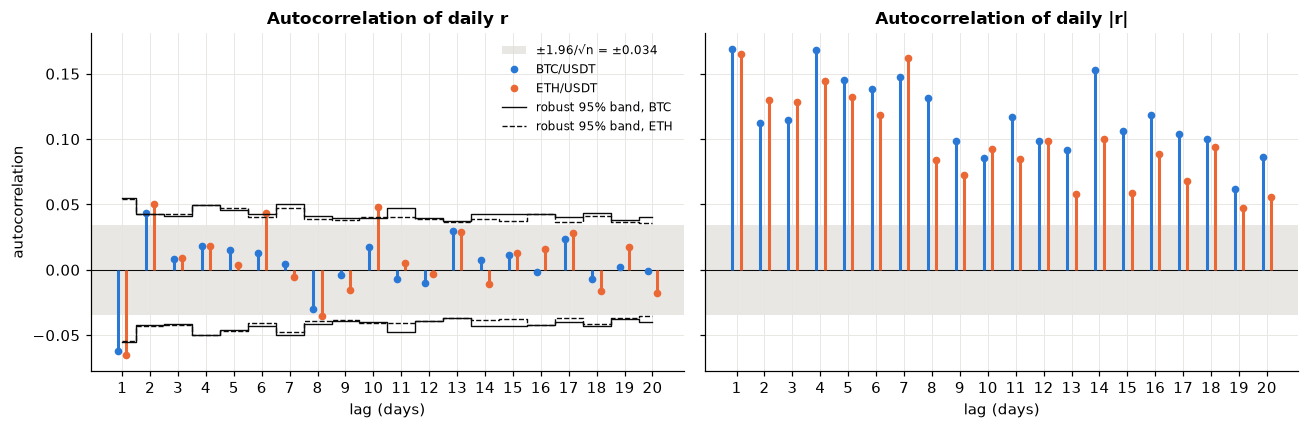

n = {('BTC', 'r'): 3248, ('BTC', '|r|'): 3248, ('ETH', 'r'): 3248, ('ETH', '|r|'): 3248}


1      2      3      4      5      6      7      8      9     10     11     12     13     14     15     16     17     18     19     20  \
BTC r   -0.062  0.044  0.008  0.018  0.015  0.013  0.004 -0.030 -0.004  0.017 -0.007 -0.010  0.029  0.008  0.011 -0.001  0.023 -0.007  0.002 -0.001   
    |r|  0.169  0.113  0.115  0.168  0.145  0.139  0.147  0.132  0.098  0.086  0.117  0.098  0.091  0.153  0.106  0.118  0.104  0.100  0.062  0.086   
ETH r   -0.065  0.050  0.009  0.019  0.003  0.044 -0.006 -0.035 -0.015  0.048  0.006 -0.003  0.029 -0.011  0.013  0.016  0.028 -0.016  0.018 -0.018   
    |r|  0.165  0.130  0.129  0.145  0.132  0.119  0.162  0.084  0.073  0.092  0.085  0.098  0.058  0.100  0.059  0.089  0.068  0.094  0.047  0.056   

         outside ±1.96/√n (i.i.d.)  outside robust band  
BTC r                            2                    2  
    |r|                         20                 <NA>  
ETH r                            5                    4  
    |r|                         20                 <NA>

In [18]:
acfs, n_obs = {}, {}
for a in SYMBOLS:
    for name, series in [("r", daily[a]), ("|r|", daily[a].abs())]:
        acfs[(a, name)], n_obs[(a, name)] = acf(series, max_lag=20)
acf_table = pd.DataFrame(acfs)
band = 1.96 / math.sqrt(min(n_obs.values()))
robust = pd.DataFrame({a: acf_robust_band(daily[a], max_lag=20) for a in SYMBOLS})

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, name in zip(axes, ["r", "|r|"]):
    ax.axhspan(-band, band, color="#d9d8d3", alpha=0.6, lw=0, label=f"±1.96/√n = ±{band:.3f}")
    ax.axhline(0, color="#0b0b0b", lw=0.7)
    for offset, a in [(-0.15, "BTC"), (0.15, "ETH")]:
        lags = acf_table.index + offset
        ax.vlines(lags, 0, acf_table[(a, name)], color=COLORS[a], lw=2)
        ax.plot(lags, acf_table[(a, name)], "o", color=COLORS[a], ms=4, label=f"{a}/USDT")
    if name == "r":
        for a, ls in [("BTC", "-"), ("ETH", "--")]:
            ax.step(acf_table.index, robust[a], where="mid", color="#0b0b0b", lw=0.9, ls=ls,
                    label=f"robust 95% band, {a}")
            ax.step(acf_table.index, -robust[a], where="mid", color="#0b0b0b", lw=0.9, ls=ls)
    ax.set_title(f"Autocorrelation of daily {name}")
    ax.set_xlabel("lag (days)")
    ax.set_xticks(range(1, 21))
axes[0].set_ylabel("autocorrelation")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

outside = (acf_table.abs() > band).sum().rename("outside ±1.96/√n (i.i.d.)")
outside_robust = pd.Series({(a, "r"): int((acf_table[(a, "r")].abs() > robust[a]).sum()) for a in SYMBOLS},
                           name="outside robust band")
print(f"n = {n_obs}")
pd.concat([acf_table.round(3).T, outside, outside_robust], axis=1).astype({"outside robust band": "Int64"})

**Daily |return| over time.** Each vertical line is one day's absolute return. Streaks show up as
dense dark stretches; calm periods as low, sparse stretches.

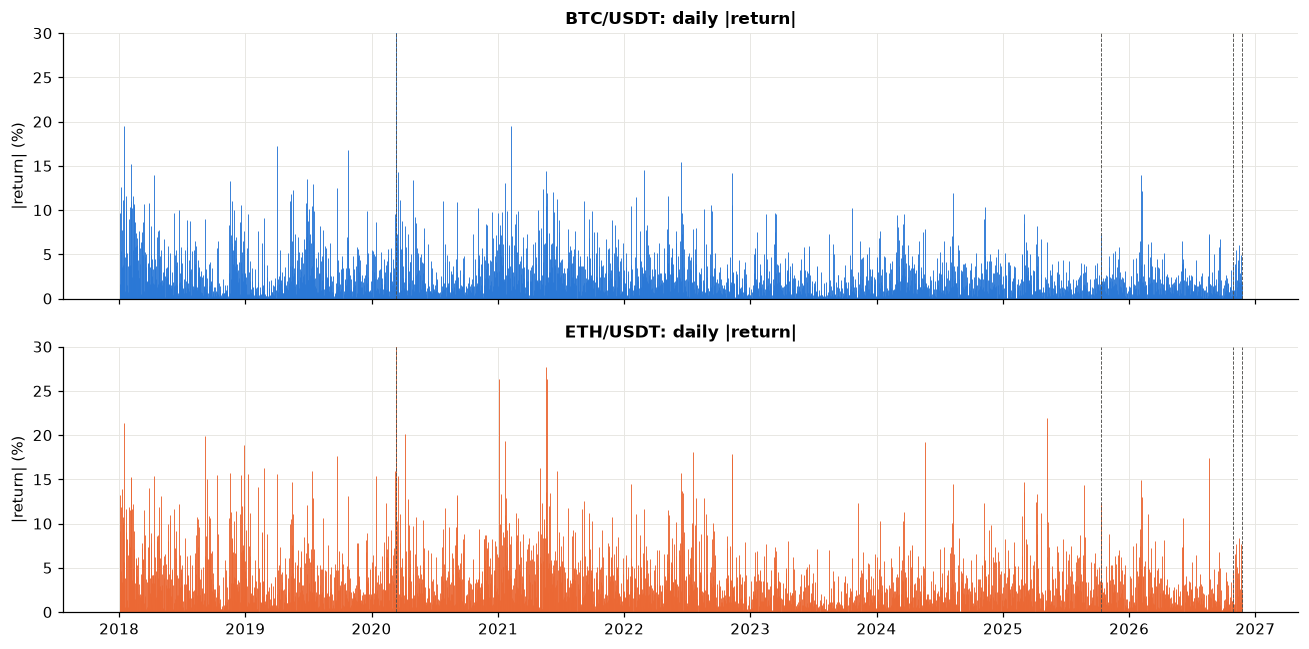

y-axis cut at 30%. Days above it: {'BTC': ['2020-03-12'], 'ETH': ['2020-03-12']}


In [19]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, sharey=True)
for ax, a in zip(axes, SYMBOLS):
    r = daily[a].abs()
    ax.vlines(r.index, 0, 100 * r, color=COLORS[a], lw=0.6)
    ax.set_title(f"{a}/USDT: daily |return|")
    ax.set_ylabel("|return| (%)")
    for day in EVENTS:
        ax.axvline(pd.Timestamp(day, tz="UTC"), color=MUTED, lw=0.6, ls="--")
axes[1].set_ylim(0, 30)
fig.tight_layout()
plt.show()
print("y-axis cut at 30%. Days above it:",
      {a: [str(d.date()) for d in daily[a].index[daily[a].abs() > 0.30]] for a in SYMBOLS})

**Conditional probability of a big day.** Big day = |z| > 2 (past-only). For every pair of
consecutive days where both z values exist, we count how often today is big, split by whether
yesterday was big. `n_days` is the number of days in each case.

Note: yesterday's big return is one of the 30 days inside today's past-only σ, which pushes
today's σ up and makes "big today" harder to reach. If anything, this makes the gap between the two
rows smaller than it would be with a σ that excluded yesterday.

In [20]:
cond = []
for a in SYMBOLS:
    t = conditional_big_day(z[a], k=BIG_Z)
    t["asset"] = a
    cond.append(t)
cond = pd.concat(cond).reset_index().set_index(["asset", "condition"])
lift = (cond["p_big_today"].xs("big yesterday", level="condition")
        / cond["p_big_today"].xs("not big yesterday", level="condition"))
display(cond.assign(p_big_today=lambda d: (100 * d["p_big_today"]).round(2))
        .rename(columns={"p_big_today": "P(big today) (%)"}))
print("P(big | big yesterday) / P(big | not big yesterday):", lift.round(2).to_dict())

n_days  n_big_today  P(big today) (%)
asset condition                                               
BTC   big yesterday         216           33             15.28
      not big yesterday    3001          183              6.10
ETH   big yesterday         227           22              9.69
      not big yesterday    2990          205              6.86

P(big | big yesterday) / P(big | not big yesterday): {'BTC': 2.51, 'ETH': 1.41}


## Part 5 — The √t rule with real data (H5)

If returns were independent from one period to the next and had the same σ, the σ of a sum of N
periods would be σ·√N: a daily σ would be the hourly σ × √24, and a weekly σ the daily σ × √7.
Here this is checked, not assumed.

**Hourly → daily, by month.** For each calendar month: σ of the month's hourly returns × √24, vs σ
of the same month's daily returns. The 24 hourly candles of a UTC day make exactly that day's
daily return (section 0 showed that the closes match). The ratio `daily σ / (hourly σ × √24)` is 1
if the rule holds; above 1 means the daily σ is larger than the rule predicts.

**Daily → weekly.** Weeks run Monday → Sunday (UTC); the weekly return is Sunday close / previous
Sunday close − 1, only for weeks with all 7 daily candles. **Post-inspection:** a month has only
4–5 weeks, and a std computed from 4–5 numbers is very noisy. The scatter therefore groups weeks by
**calendar quarter** (about 13 weeks); the table also shows month and year groupings.

**Post-inspection: what "the rule holds" looks like.** A std computed from few returns tends to come
out **below** the true σ. So even if the √t rule held exactly, the median ratio would be below 1,
and fewer than half of the groups would be above 1. The columns `median ratio if rule holds` and
`share > 1 if rule holds (%)` give those values for normal returns with the group sizes of each row
(`sqrt_t_null_ratio` in `src/volatility.py`). Compare the observed columns with **these**, not with 1.

In [21]:
def naive(index):
    return index.tz_localize(None)


def group_series(labels, index):
    return pd.Series(labels, index=index)


comparisons = {}
for a in SYMBOLS:
    h, d = hourly[a], daily[a]
    for freq, name in [("M", "month"), ("Y", "year")]:
        comparisons[("hourly × √24 vs daily", name, a)] = sqrt_t_by_group(
            h, d, group_series(naive(h.index).to_period(freq), h.index),
            group_series(naive(d.index).to_period(freq), d.index), periods=24)
    wk = weekly_returns_from_daily(candles[(a, "1d")]["close"])
    sunday = week_sunday(d.index)
    in_week = sunday.isin(naive(wk.index))
    d_in = d[in_week]
    for freq, name in [("M", "month"), ("Q", "quarter"), ("Y", "year")]:
        comparisons[("daily × √7 vs weekly", name, a)] = sqrt_t_by_group(
            d_in, wk, group_series(sunday[in_week].to_period(freq), d_in.index),
            group_series(naive(wk.index).to_period(freq), wk.index), periods=7)

sqrt_rows = []
for (comparison, grouping, a), out in comparisons.items():
    q = out["ratio_coarse_over_scaled"]
    null = pd.DataFrame([sqrt_t_null_ratio(int(n)) for n in out["n_coarse"]], columns=["median", "p_above"])
    sqrt_rows.append({"comparison": comparison, "grouping": grouping, "asset": a,
                      "groups": len(out), "median returns per group (coarse)": out["n_coarse"].median(),
                      "median ratio": q.median(), "median ratio if rule holds": null["median"].median(),
                      "p25": q.quantile(0.25), "p75": q.quantile(0.75),
                      "share > 1 (%)": 100 * (q > 1).mean(),
                      "share > 1 if rule holds (%)": 100 * null["p_above"].mean()})
sqrt_table = pd.DataFrame(sqrt_rows).set_index(["comparison", "grouping", "asset"])
sqrt_table.round(3)

groups  median returns per group (coarse)  median ratio  median ratio if rule holds    p25    p75  share > 1 (%)  \
comparison            grouping asset                                                                                                                     
hourly × √24 vs daily month    BTC       107                               31.0         0.999                       0.989  0.907  1.063         49.533   
                      year     BTC         9                              365.0         1.010                       0.999  0.942  1.036         55.556   
daily × √7 vs weekly  month    BTC       107                                4.0         0.893                       0.891  0.699  1.146         42.056   
                      quarter  BTC        36                               13.0         0.932                       0.972  0.842  1.038         30.556   
                      year     BTC         9                               52.0         0.980                       0.993  0.897  1.011         33.333   
hourly × √24 vs daily month    ETH       107                               31.0         1.010                       0.989  0.934  1.089         53.271   
                      year     ETH         9                              365.0         1.014                       0.999  1.013  1.036         77.778   
daily × √7 vs weekly  month    ETH       107                                4.0         0.915                       0.891  0.663  1.155         42.991   
                      quarter  ETH        36                               13.0         0.966                       0.972  0.810  1.088         47.222   
                      year     ETH         9                               52.0         0.994                       0.993  0.950  1.014         44.444   

                                      share > 1 if rule holds (%)  
comparison            grouping asset                               
hourly × √24 vs daily month    BTC                         46.531  
                      year     BTC                         49.008  
daily × √7 vs weekly  month    BTC                         39.727  
                      quarter  BTC                         44.539  
                      year     BTC                         47.353  
hourly × √24 vs daily month    ETH                         46.531  
                      year     ETH                         49.008  
daily × √7 vs weekly  month    ETH                         39.727  
                      quarter  ETH                         44.539  
                      year     ETH                         47.353

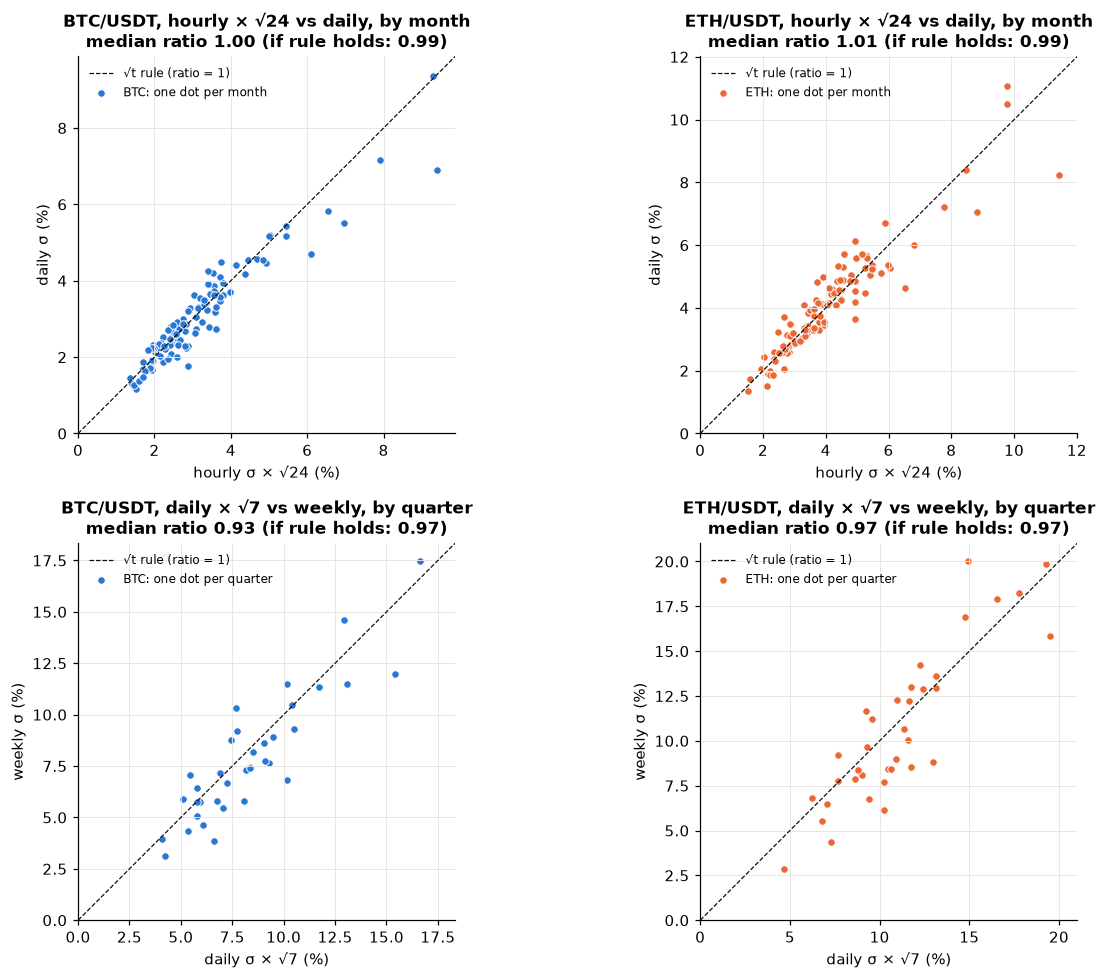

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
panels = [("hourly × √24 vs daily", "month", "hourly σ × √24 (%)", "daily σ (%)"),
          ("daily × √7 vs weekly", "quarter", "daily σ × √7 (%)", "weekly σ (%)")]
for row, (comparison, grouping, xlabel, ylabel) in enumerate(panels):
    for col, a in enumerate(SYMBOLS):
        ax = axes[row, col]
        out = comparisons[(comparison, grouping, a)]
        x, y = 100 * out["scaled_fine_vol"], 100 * out["coarse_vol"]
        top = 1.05 * max(x.max(), y.max())
        ax.plot([0, top], [0, top], color="#0b0b0b", lw=0.8, ls="--", label="√t rule (ratio = 1)")
        ax.scatter(x, y, s=24, color=COLORS[a], edgecolor="white", linewidth=0.6,
                   label=f"{a}: one dot per {grouping}")
        ax.set_xlim(0, top); ax.set_ylim(0, top); ax.set_aspect("equal")
        med = sqrt_table.loc[(comparison, grouping, a), "median ratio"]
        null_med = sqrt_table.loc[(comparison, grouping, a), "median ratio if rule holds"]
        ax.set_title(f"{a}/USDT, {comparison}, by {grouping}\nmedian ratio {med:.2f} "
                     f"(if rule holds: {null_med:.2f})")
        ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
        ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

## Part 6 — Weekend (H6)

**Saturday + Sunday vs Monday–Friday, daily returns.** The weekday is the UTC weekday of the
candle's open: Saturday's return goes from Friday's close (Saturday 00:00) to Saturday's close
(Sunday 00:00). The table shows the daily σ (not annualized) of each group, their ratio, and how
many days each group has.

In [23]:
weekend_rows = []
for a in SYMBOLS:
    r = daily[a].dropna()
    for year, group in list(r.groupby(r.index.year)) + [("all", r)]:
        wknd = group.index.day_of_week >= 5
        weekend_rows.append({"asset": a, "year (UTC)": year,
                             "weekend σ (%)": 100 * group[wknd].std(ddof=1),
                             "weekday σ (%)": 100 * group[~wknd].std(ddof=1),
                             "n weekend": int(wknd.sum()), "n weekday": int((~wknd).sum())})
weekend = pd.DataFrame(weekend_rows)
weekend["ratio weekend / weekday"] = weekend["weekend σ (%)"] / weekend["weekday σ (%)"]
weekend = weekend.set_index(["year (UTC)", "asset"]).unstack("asset")
weekend.columns = weekend.columns.swaplevel(0, 1)
weekend = weekend.sort_index(axis=1, level=0, sort_remaining=False)
weekend.round(3)

asset                BTC                                                                     ETH                                                          
           weekend σ (%) weekday σ (%) n weekend n weekday ratio weekend / weekday weekend σ (%) weekday σ (%) n weekend n weekday ratio weekend / weekday
year (UTC)                                                                                                                                                
2018               3.558         4.629       104       260                   0.769         4.675         6.093       104       260                   0.767
2019               3.166         3.754       104       261                   0.843         3.986         4.304       104       261                   0.926
2020               2.668         4.345       104       262                   0.614         4.386         5.470       104       262                   0.802
2021               2.973         4.661       104       261                   0.638         4.680         6.021       104       261                   0.777
2022               2.124         3.719       105       260                   0.571         3.326         4.952       105       260                   0.672
2023               1.427         2.580       105       260                   0.553         1.759         2.685       105       260                   0.655
2024               1.733         3.099       104       262                   0.559         2.271         3.751       104       262                   0.605
2025               1.793         2.322       104       261                   0.772         3.303         4.149       104       261                   0.796
2026               1.574         2.613        94       233                   0.603         2.502         3.459        94       233                   0.723
all                2.447         3.645       928      2320                   0.671         3.588         4.697       928      2320                   0.764

**Hourly volatility by hour (UTC) and day of the week.** Each cell is the std of all hourly returns
(2018–2026) whose candle opened at that hour on that UTC weekday, in basis points (1 bp = 0.01%).
Darker = more volatile.

**Post-inspection: a robust version.** A std can be driven by a single huge hour. The second figure
shows the **median |hourly return|** of each cell instead, which one extreme hour cannot move. The
table under it gives both measures, and the std of the max-std cell after dropping its single
largest |return|. The second row of tick labels is the same hour in CDMX (UTC−6); for CDMX
hours 18–23 the CDMX weekday is the previous day (rows stay in UTC weekdays). Mexico City used
summer time (UTC−5) until October 2022, so before that the CDMX label is one hour off in summer.

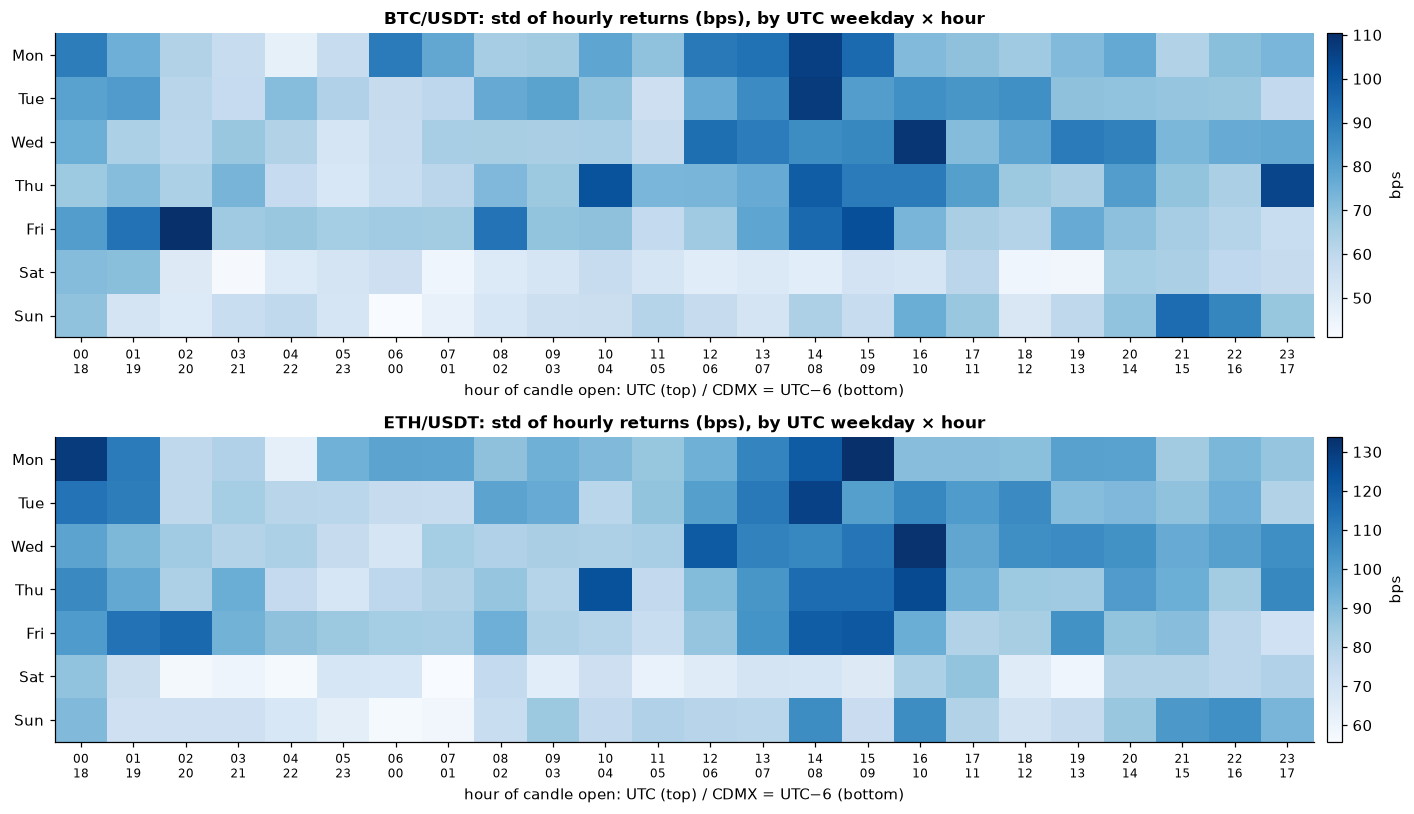

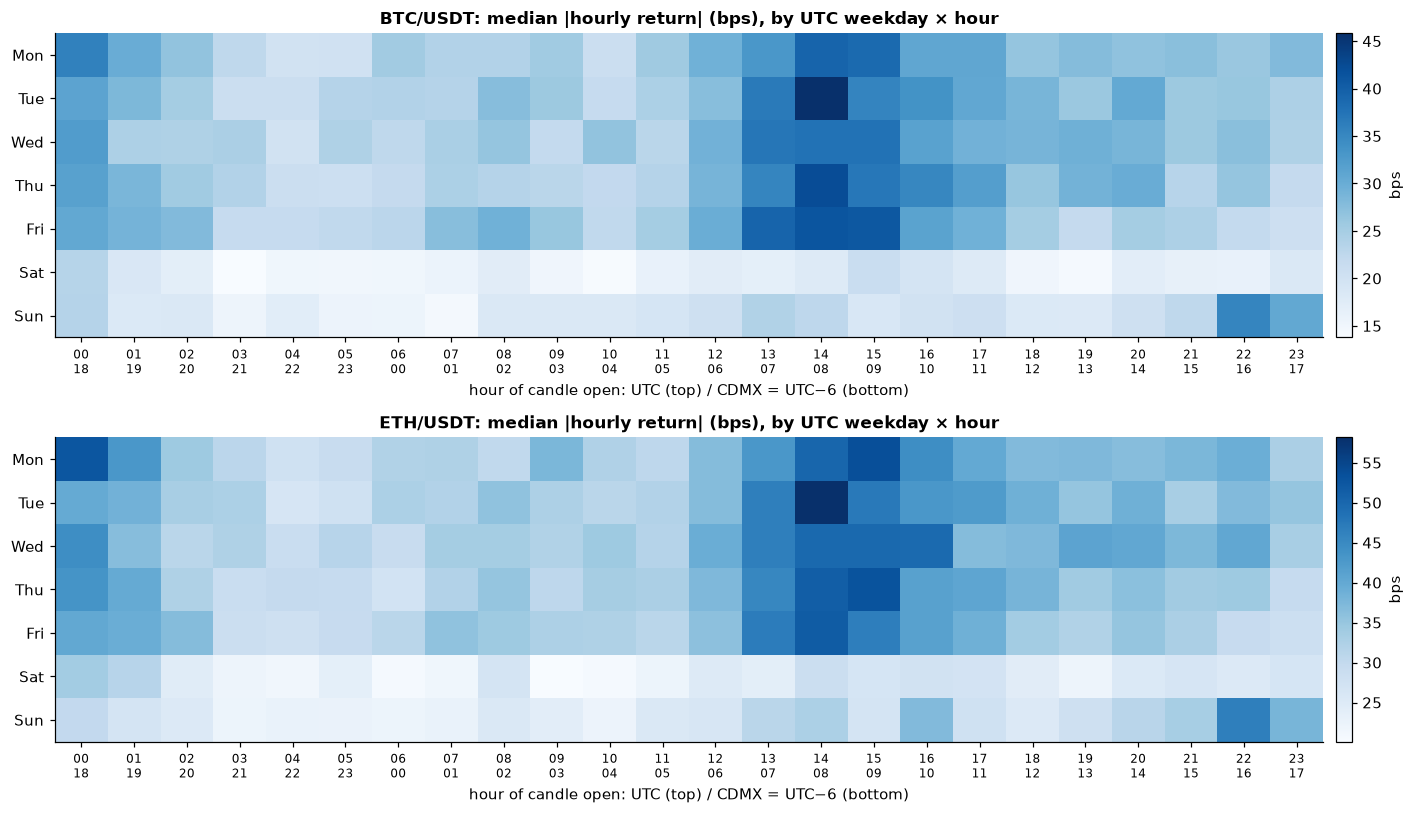

min hours per cell: 460


min cell (bps)      min at  max cell (bps)      max at  max / min  max cell std without its largest |r| (bps)   largest |r| in max cell
asset measure                                                                                                                                            
BTC   std                  41.00  Sun 06 UTC          110.40  Fri 02 UTC       2.69                                       74.84  2020-03-13 02:00 (17.4%)
      median |r|           13.79  Sat 03 UTC           45.84  Tue 14 UTC       3.32                                         NaN                       NaN
ETH   std                  55.81  Sat 07 UTC          133.71  Mon 15 UTC       2.40                                      125.18  2019-01-14 15:00 (10.3%)
      median |r|           20.11  Sat 09 UTC           58.16  Tue 14 UTC       2.89                                         NaN                       NaN

In [24]:
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
heat, heat_n = {}, {}
for a in SYMBOLS:
    r = hourly[a].dropna()
    key = [r.index.day_of_week, r.index.hour]
    heat[a] = (r.groupby(key).std(ddof=1) * 1e4).unstack()
    heat_n[a] = r.groupby(key).size().unstack()
heat_med = {}
for a in SYMBOLS:
    r = hourly[a].dropna()
    heat_med[a] = (r.abs().groupby([r.index.day_of_week, r.index.hour]).median() * 1e4).unstack()


def plot_heat(tables, what):
    fig, axes = plt.subplots(2, 1, figsize=(13, 7.5))
    for ax, a in zip(axes, SYMBOLS):
        im = ax.imshow(tables[a].to_numpy(), cmap="Blues", aspect="auto")
        ax.set_yticks(range(7), DAYS)
        ax.set_xticks(range(24), [f"{h:02d}\n{(h + CDMX_OFFSET_H) % 24:02d}" for h in range(24)], fontsize=8)
        ax.set_xlabel("hour of candle open: UTC (top) / CDMX = UTC−6 (bottom)")
        ax.set_title(f"{a}/USDT: {what} (bps), by UTC weekday × hour")
        ax.grid(False)
        fig.colorbar(im, ax=ax, label="bps", fraction=0.025, pad=0.01)
    fig.tight_layout()
    plt.show()


plot_heat(heat, "std of hourly returns")
plot_heat(heat_med, "median |hourly return|")

hour_rows = []
for a in SYMBOLS:
    r = hourly[a].dropna()
    for measure, table in [("std", heat[a]), ("median |r|", heat_med[a])]:
        flat = table.stack()
        (dmax, hmax), (dmin, hmin) = flat.idxmax(), flat.idxmin()
        row = {"asset": a, "measure": measure,
               "min cell (bps)": flat.min(), "min at": f"{DAYS[dmin]} {hmin:02d} UTC",
               "max cell (bps)": flat.max(), "max at": f"{DAYS[dmax]} {hmax:02d} UTC",
               "max / min": flat.max() / flat.min()}
        if measure == "std":
            cell = r[(r.index.day_of_week == dmax) & (r.index.hour == hmax)]
            top = cell.abs().idxmax()
            row["max cell std without its largest |r| (bps)"] = cell.drop(top).std(ddof=1) * 1e4
            row["largest |r| in max cell"] = f"{top:%Y-%m-%d %H:%M} ({100 * cell.loc[top]:.1f}%)"
        hour_rows.append(row)
print(f"min hours per cell: {int(min(heat_n[a].min().min() for a in SYMBOLS))}")
hour_table = pd.DataFrame(hour_rows).set_index(["asset", "measure"])
hour_table.round(2)

## Part 7 — Cost vs typical move (H7)

**Typical move** over a horizon t = σ·√t, with σ = BTC's daily σ of the last 30 days
(2026-10-25 → 2026-11-23): 1 hour = σ·√(1/24), 1 day = σ, 1 week = σ·√7. Only the 1-day value is
measured directly; 1 h and 1 week **assume** the √t rule (Part 5 shows how well it held). As a
cross-check, the 1-hour move is also measured from the hourly returns of the same 30 days, and
the cost is divided by it too (columns `… / measured σ`).

"Typical move" here means **one σ**. With fat tails (Part 3), most days are calmer than σ and a few
are much wilder, so the median |move| is smaller than σ: the cost is a larger share of the median
move than this table shows.

**Costs** are notebook 07's round trips for BTC/USDT, market order in and out (taker → taker) at
1k–10k USDT: **spot 20.00 bps** and **USDⓈ-M perpetual 10.02 bps**. They are carried over, not
re-measured here. The perpetual cost excludes funding (M8). `cost / move` is the share of a typical
move that the round trip costs.

In [25]:
COST_BPS = {"spot": 20.00, "perp": 10.02}      # notebook 07, BTC taker → taker, 1k–10k USDT
last_days = daily["BTC"].iloc[-WINDOW:]
sigma_d = last_days.std(ddof=1)
last_hours = hourly["BTC"].loc[last_days.index[0]:].dropna()
sigma_h_measured = last_hours.std(ddof=1)
print(f"BTC daily σ: {pct(sigma_d, 3)} from {len(last_days)} days "
      f"({last_days.index[0].date()} → {last_days.index[-1].date()}); "
      f"hourly σ measured: {pct(sigma_h_measured, 3)} from {len(last_hours)} hours")

moves = []
for horizon, days_in, measured in [("1 hour", 1 / 24, sigma_h_measured), ("1 day", 1, sigma_d), ("1 week", 7, None)]:
    move_bps = sigma_d * math.sqrt(days_in) * 1e4
    moves.append({"horizon": horizon, "typical move σ·√t (bps)": move_bps,
                  "measured σ at this horizon (bps)": measured * 1e4 if measured is not None else np.nan,
                  "move source": "measured" if horizon == "1 day" else "assumed √t from daily σ",
                  "spot cost / move (%)": 100 * COST_BPS["spot"] / move_bps,
                  "perp cost / move (%)": 100 * COST_BPS["perp"] / move_bps,
                  "spot cost / measured σ (%)": 100 * COST_BPS["spot"] / (measured * 1e4) if measured is not None else np.nan,
                  "perp cost / measured σ (%)": 100 * COST_BPS["perp"] / (measured * 1e4) if measured is not None else np.nan})
moves = pd.DataFrame(moves).set_index("horizon")
moves.round(2)

BTC daily σ: 2.415% from 30 days (2026-10-25 → 2026-11-23); hourly σ measured: 0.578% from 720 hours


,typical move σ·√t (bps),measured σ at this horizon (bps),move source,spot cost / move (%),perp cost / move (%),spot cost / measured σ (%),perp cost / measured σ (%)
horizon,,,,,,,
1 hour,49.30,57.83,assumed √t from daily σ,40.57,20.32,34.58,17.33
1 day,241.52,241.52,measured,8.28,4.15,8.28,4.15
1 week,639.01,NaN,assumed √t from daily σ,3.13,1.57,NaN,NaN


## Findings

One row per question. **Measured** = computed from the candles in this notebook. **Assumed** =
taken from elsewhere or from a rule that is not checked at that point.

In [26]:
btc_cur, eth_cur = current.loc["BTC"], current.loc["ETH"]
t3 = tails.xs("past-only (30 d)", level="sigma")
hd = sqrt_table.xs(("hourly × √24 vs daily", "month"), level=["comparison", "grouping"])
dw = sqrt_table.xs(("daily × √7 vs weekly", "quarter"), level=["comparison", "grouping"])
wk_all = weekend.loc["all"]
findings = pd.DataFrame([
    {"question": "H1 current 30-d vol and percentile",
     "measured figure": f"BTC {btc_cur['current 30-d vol (%)']:.1f}% (pct {btc_cur['percentile within 2018–2026 (%)']:.0f}), "
                        f"ETH {eth_cur['current 30-d vol (%)']:.1f}% (pct {eth_cur['percentile within 2018–2026 (%)']:.0f})",
     "n": f"30 days; {int(btc_cur['n windows'])} windows",
     "measured vs assumed": "measured; annualized with √365 (convention)"},
    {"question": "H2 ETH/BTC vol ratio, correlation",
     "measured figure": f"ratio {pair.loc['all', 'ratio ETH/BTC']:.2f} (all days), 30-d ratio > 1 on "
                        f"{100 * (ratio30 > 1).mean():.0f}% of days; corr {pair.loc['all', 'corr BTC–ETH']:.2f} "
                        f"(yearly {pair['corr BTC–ETH'].drop('all').min():.2f}–{pair['corr BTC–ETH'].drop('all').max():.2f})",
     "n": f"{int(pair.loc['all', 'n days'])} days",
     "measured vs assumed": "measured"},
    {"question": "H3 tails |z| > 4 vs normal",
     "measured figure": "observed vs expected normal / t(29): " + "; ".join(
         f"{a} {t3.loc[(a, '|z| > 4'), 'observed']} vs {t3.loc[(a, '|z| > 4'), 'expected_normal']:.2f} / "
         f"{t3.loc[(a, '|z| > 4'), 'expected_t29']:.2f}" for a in SYMBOLS),
     "n": f"{t3.loc[('BTC', '|z| > 4'), 'n_days']} days",
     "measured vs assumed": "measured; 'expected' assumes normal returns (σ known, or σ estimated from 30 d → t29)"},
    {"question": "H4 clustering",
     "measured figure": f"P(big | big yesterday) / P(big | not) = BTC {lift['BTC']:.2f}, ETH {lift['ETH']:.2f}; "
                        f"|r| lags outside i.i.d. band: BTC {outside[('BTC', '|r|')]}/20, ETH {outside[('ETH', '|r|')]}/20; "
                        f"r lags outside robust band: BTC {outside_robust[('BTC', 'r')]}/20, ETH {outside_robust[('ETH', 'r')]}/20",
     "n": f"big-yesterday days: BTC {cond.loc[('BTC', 'big yesterday'), 'n_days']}, ETH {cond.loc[('ETH', 'big yesterday'), 'n_days']}",
     "measured vs assumed": "measured; i.i.d. band for |r|, heteroskedasticity-robust band for r"},
    {"question": "H5 √t rule",
     "measured figure": "median ratio observed (if rule holds): daily/(hourly·√24) by month: " + ", ".join(
         f"{a} {hd.loc[a, 'median ratio']:.2f} ({hd.loc[a, 'median ratio if rule holds']:.2f})" for a in SYMBOLS)
         + "; weekly/(daily·√7) by quarter: " + ", ".join(
         f"{a} {dw.loc[a, 'median ratio']:.2f} ({dw.loc[a, 'median ratio if rule holds']:.2f})" for a in SYMBOLS),
     "n": f"{int(hd.loc['BTC', 'groups'])} months; {int(dw.loc['BTC', 'groups'])} quarters",
     "measured vs assumed": "measured; 'if rule holds' assumes normal returns (quarter grouping and reference are post-inspection)"},
    {"question": "H6 weekend and hour",
     "measured figure": f"weekend/weekday σ: BTC {wk_all[('BTC', 'ratio weekend / weekday')]:.2f}, "
                        f"ETH {wk_all[('ETH', 'ratio weekend / weekday')]:.2f}; hour×weekday max/min of median |r|: "
                        + ", ".join(f"{a} {hour_table.loc[(a, 'median |r|'), 'max / min']:.1f} "
                                    f"(max {hour_table.loc[(a, 'median |r|'), 'max at']}, min {hour_table.loc[(a, 'median |r|'), 'min at']})"
                                    for a in SYMBOLS),
     "n": f"{int(wk_all[('BTC', 'n weekend')])} weekend / {int(wk_all[('BTC', 'n weekday')])} weekdays; "
          f"≥ {int(heat_n['BTC'].min().min())} hours per cell",
     "measured vs assumed": "measured; median |r| used because the BTC max std cell is one hour; CDMX label assumes UTC−6"},
    {"question": "H7 cost vs typical BTC move",
     "measured figure": "spot / perp cost as % of move: " + "; ".join(
         f"{h} {moves.loc[h, 'spot cost / move (%)']:.1f}% / {moves.loc[h, 'perp cost / move (%)']:.1f}%" for h in moves.index)
         + f" (1 h with measured hourly σ: {moves.loc['1 hour', 'spot cost / measured σ (%)']:.1f}% / "
           f"{moves.loc['1 hour', 'perp cost / measured σ (%)']:.1f}%)",
     "n": f"{len(last_days)} days (σ); costs from notebook 07",
     "measured vs assumed": "σ measured; 1 h and 1 w moves assume √t; costs assumed from 07 (no funding)"},
]).set_index("question")
with pd.option_context("display.max_colwidth", 200):
    display(findings)

,measured figure,n,measured vs assumed
question,,,
H1 current 30-d vol and percentile,"BTC 46.1% (pct 35), ETH 64.7% (pct 37)",30 days; 3219 windows,measured; annualized with √365 (convention)
"H2 ETH/BTC vol ratio, correlation","ratio 1.32 (all days), 30-d ratio > 1 on 90% of days; corr 0.82 (yearly 0.76–0.92)",3248 days,measured
H3 tails |z| > 4 vs normal,observed vs expected normal / t(29): BTC 33 vs 0.20 / 1.29; ETH 24 vs 0.20 / 1.29,3218 days,"measured; 'expected' assumes normal returns (σ known, or σ estimated from 30 d → t29)"
H4 clustering,"P(big | big yesterday) / P(big | not) = BTC 2.51, ETH 1.41; |r| lags outside i.i.d. band: BTC 20/20, ETH 20/20; r lags outside robust band: BTC 2/20, ETH 4/20","big-yesterday days: BTC 216, ETH 227","measured; i.i.d. band for |r|, heteroskedasticity-robust band for r"
H5 √t rule,"median ratio observed (if rule holds): daily/(hourly·√24) by month: BTC 1.00 (0.99), ETH 1.01 (0.99); weekly/(daily·√7) by quarter: BTC 0.93 (0.97), ETH 0.97 (0.97)",107 months; 36 quarters,measured; 'if rule holds' assumes normal returns (quarter grouping and reference are post-inspection)
H6 weekend and hour,"weekend/weekday σ: BTC 0.67, ETH 0.76; hour×weekday max/min of median |r|: BTC 3.3 (max Tue 14 UTC, min Sat 03 UTC), ETH 2.9 (max Tue 14 UTC, min Sat 09 UTC)",928 weekend / 2320 weekdays; ≥ 460 hours per cell,measured; median |r| used because the BTC max std cell is one hour; CDMX label assumes UTC−6
H7 cost vs typical BTC move,spot / perp cost as % of move: 1 hour 40.6% / 20.3%; 1 day 8.3% / 4.1%; 1 week 3.1% / 1.6% (1 h with measured hourly σ: 34.6% / 17.3%),30 days (σ); costs from notebook 07,σ measured; 1 h and 1 w moves assume √t; costs assumed from 07 (no funding)


## Key takeaways

1. **Volatility today is below its 2018–2026 middle.** The 30-day volatility on 2026-11-23 is
   **46.1%** for BTC and **64.7%** for ETH (annualized with √365). That puts them at the **35th** and
   **37th** percentiles of 3,219 windows. The range was **16.7% → 183.6%** for BTC (2023-08-13 →
   2020-04-06).
2. **ETH moves more than BTC, and in the same direction.** Over all days, ETH's volatility is
   **1.32×** BTC's, and its 30-day volatility was higher on **90%** of days. The correlation of
   daily returns is **0.82** overall and **0.76–0.92** by year.
3. **The tails are much fatter than a normal predicts, even allowing for a noisy σ.** BTC had
   **33** days with |z| > 4 (past-only). A normal would give **0.20**, and a normal with σ
   estimated from 30 days (t29) would give **1.29**. ETH had **24**.
4. **Size clusters, direction barely does.** The autocorrelation of |r| is outside the i.i.d. band
   at **20 of 20** lags for both assets (lag 1: **0.17**). For r itself, only **2** (BTC) and **4**
   (ETH) of 20 lags are outside the robust band. P(big day | big yesterday) is **15.3%** vs **6.1%**
   otherwise for BTC (n = 216 and 3,001 days), and **9.7%** vs **6.9%** for ETH.
5. **Time scales.** Hourly σ × √24 matches the daily σ in the median month (ratio **1.00** BTC,
   **1.01** ETH, vs **0.99** expected if the rule holds). From daily to weekly, ETH matches the rule
   (**0.97** vs **0.97** expected, by quarter), and BTC is below it (**0.93**, with **31%** of quarters
   above 1 vs **45%** expected). Weekend days have **0.67×** (BTC) and **0.76×** (ETH) the σ of
   weekdays. Notebook 07's spot round trip (20.00 bps) is **40.6%** of a 1-σ 1-hour BTC move under
   √t (**34.6%** with the measured hourly σ), and **3.1%** of a 1-σ 1-week move.

These are descriptions of 2018–2026 Binance spot data. Timing is not causation: nothing here says
why any of it happens.